# Auto MPG Dataset – Basic EDA and Regression

This notebook performs simple Exploratory Data Analysis (EDA), followed by the regression work from the original notebook.

**Note:** Keep `auto-mpg.csv` in the same folder as this notebook before running it.

## 1. Import libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

## 2. Load the dataset

In [4]:
df = pd.read_csv("auto-mpg.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


## 3. Basic dataset inspection

In [5]:
# Number of rows and columns
df.shape

(398, 9)

In [6]:
# Column names
df.columns

Index(['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'model year', 'origin', 'car name'],
      dtype='object')

In [7]:
# First 5 rows
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [8]:
# Last 5 rows
df.tail()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger
397,31.0,4,119.0,82,2720,19.4,82,1,chevy s-10


In [9]:
# Dataset information and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB


In [10]:
# Statistical summary
df.describe(include="all")

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
count,398.000000,398.000000,398.000000,398,398.000000,398.000000,398.000000,398.000000,398
unique,NaN,NaN,NaN,94,NaN,NaN,NaN,NaN,305
top,NaN,NaN,NaN,150,NaN,NaN,NaN,NaN,ford pinto
freq,NaN,NaN,NaN,22,NaN,NaN,NaN,NaN,6
mean,23.514573,5.454774,193.425879,NaN,2970.424623,15.568090,76.010050,1.572864,NaN
std,7.815984,1.701004,104.269838,NaN,846.841774,2.757689,3.697627,0.802055,NaN
min,9.000000,3.000000,68.000000,NaN,1613.000000,8.000000,70.000000,1.000000,NaN
25%,17.500000,4.000000,104.250000,NaN,2223.750000,13.825000,73.000000,1.000000,NaN
50%,23.000000,4.000000,148.500000,NaN,2803.500000,15.500000,76.000000,1.000000,NaN
75%,29.000000,8.000000,262.000000,NaN,3608.000000,17.175000,79.000000,2.000000,NaN


## 4. Data quality checks

In [11]:
# Missing values in each column
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64

In [12]:
# Number of duplicate rows
df.duplicated().sum()

0

In [13]:
# Data types
df.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower       object
weight            int64
acceleration    float64
model year        int64
origin            int64
car name         object
dtype: object

## 5. Clean horsepower

In [14]:
# Horsepower may be stored as text in this dataset.
# Convert it to numeric; invalid values become NaN.
df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")

# Check missing values after conversion
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64

In [15]:
# Remove rows missing the columns used in the analysis
df = df.dropna(subset=["horsepower", "mpg"]).copy()

# Check the cleaned dataset
df.shape

(392, 9)

## 6. Univariate analysis
Univariate analysis examines one variable at a time.

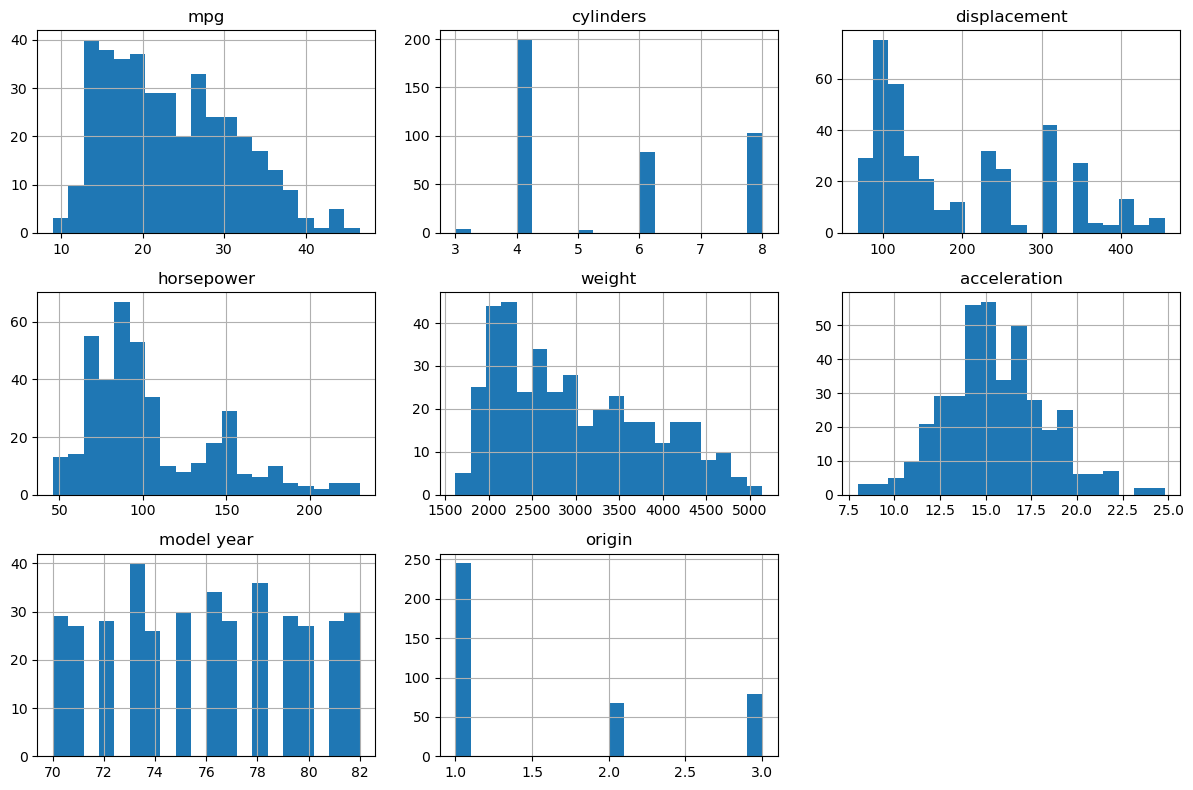

In [16]:
# Histograms for numerical columns
df.select_dtypes(include="number").hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

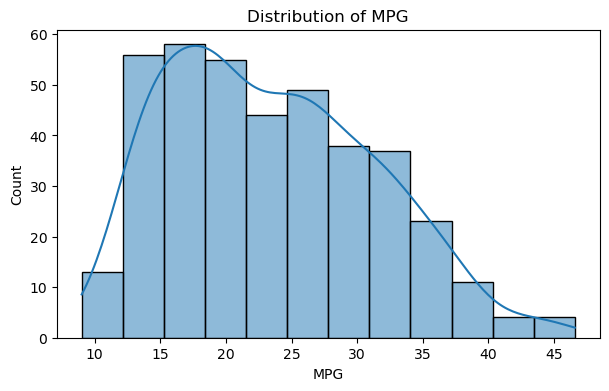

In [17]:
# Distribution of MPG
plt.figure(figsize=(7, 4))
sns.histplot(df["mpg"], kde=True)
plt.title("Distribution of MPG")
plt.xlabel("MPG")
plt.show()

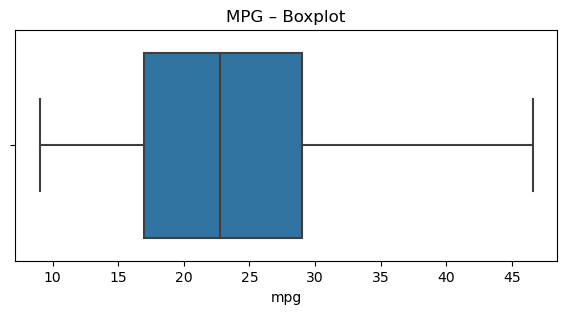

In [18]:
# Boxplot of MPG
plt.figure(figsize=(7, 3))
sns.boxplot(x=df["mpg"])
plt.title("MPG – Boxplot")
plt.show()

## 7. Bivariate analysis
Bivariate analysis examines the relationship between two variables.

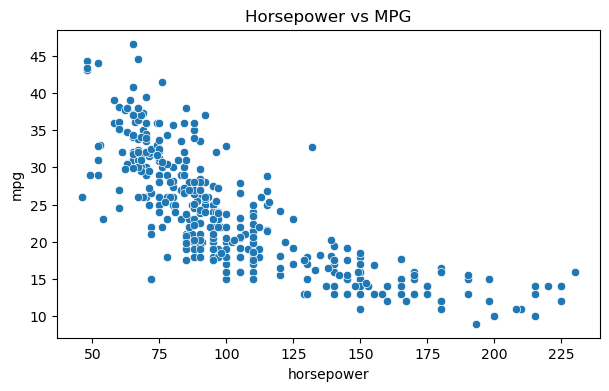

In [19]:
# Horsepower vs MPG
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="horsepower", y="mpg")
plt.title("Horsepower vs MPG")
plt.show()

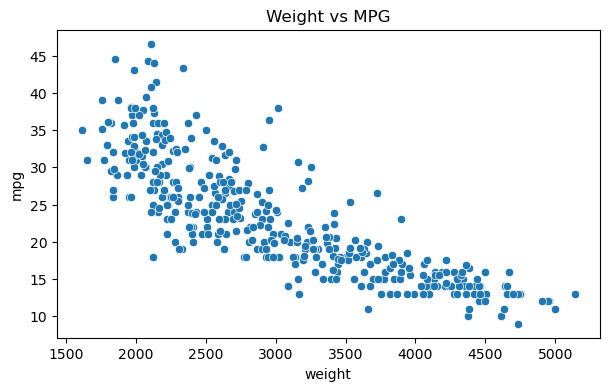

In [20]:
# Weight vs MPG
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="weight", y="mpg")
plt.title("Weight vs MPG")
plt.show()

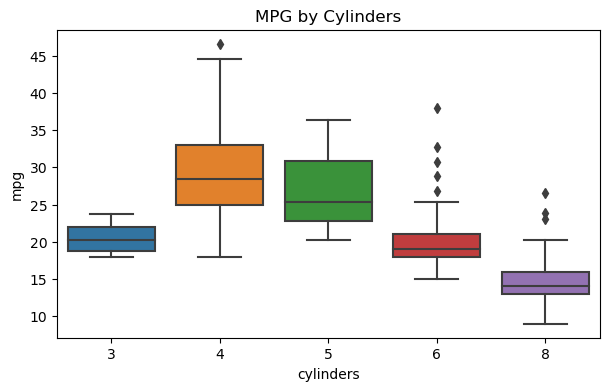

In [21]:
# MPG by number of cylinders
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="cylinders", y="mpg")
plt.title("MPG by Cylinders")
plt.show()

## 8. Correlation analysis

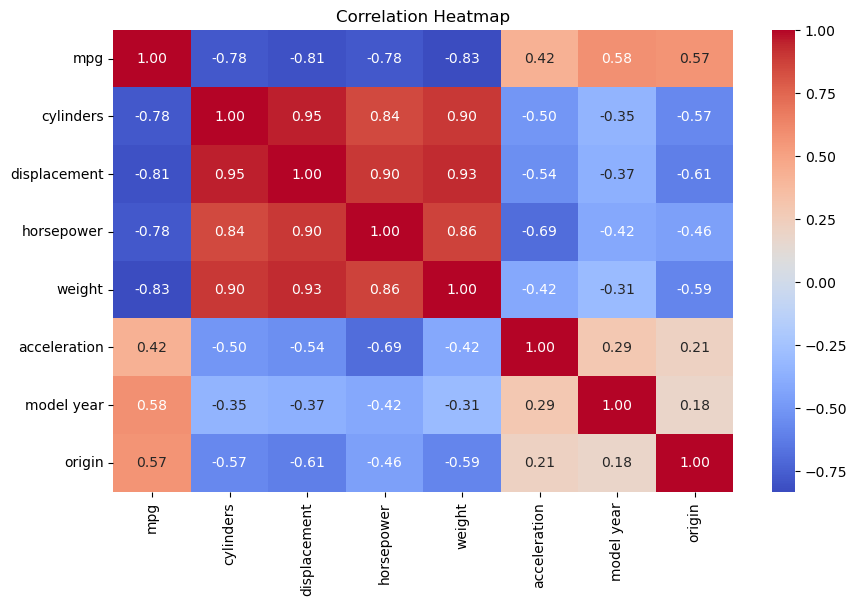

In [22]:
# Correlation between numerical columns
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## 9. Outlier check

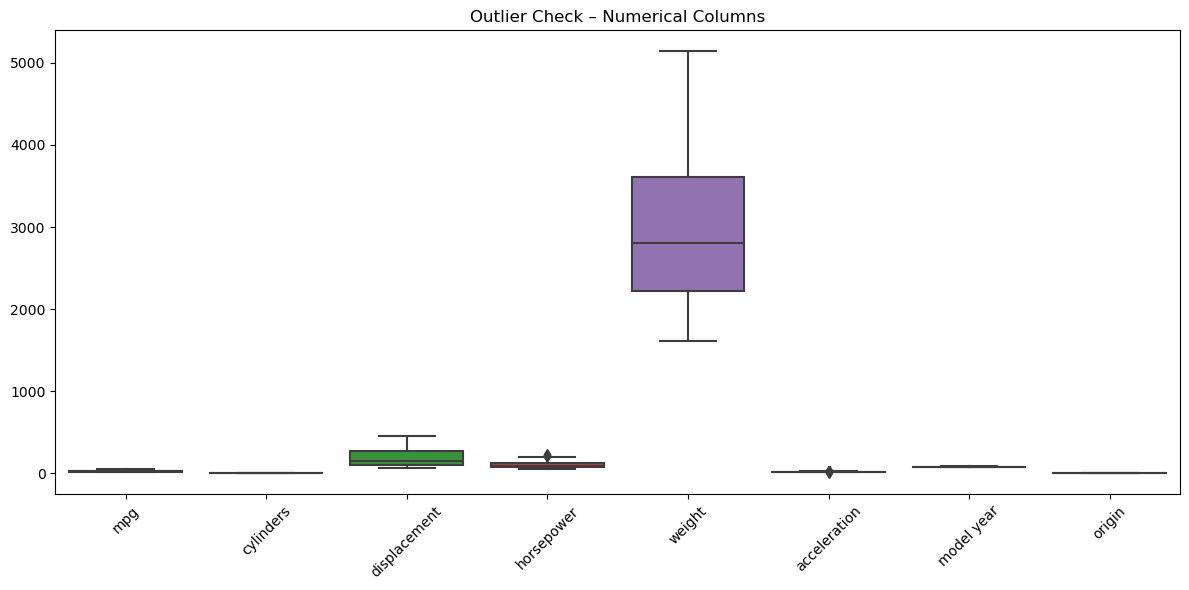

In [23]:
# Boxplots for numerical columns
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 6))
sns.boxplot(data=numeric_df)
plt.xticks(rotation=45)
plt.title("Outlier Check – Numerical Columns")
plt.tight_layout()
plt.show()

## 10. Simple EDA observations
After running the notebook, write a few observations based on your plots and summary:
- Which numerical column has the highest average?
- Does MPG tend to increase or decrease as horsepower increases?
- Does MPG tend to increase or decrease as weight increases?
- Which columns appear to have outliers?
- Which numerical features have the strongest correlation with MPG?

---
# Regression (from the original notebook)
The following section uses `horsepower` as the feature (X) and `mpg` as the target (y).

In [24]:
X = df[["horsepower"]]
y = df["mpg"]

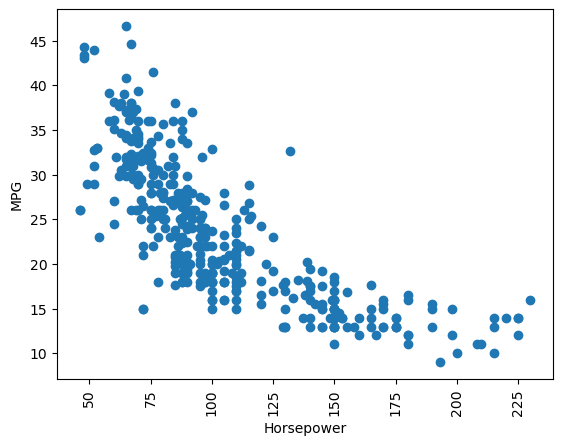

In [25]:
plt.scatter(X,y)
plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.xticks(rotation= 90)
plt.show()

### Linear Regression on Polynomial Data

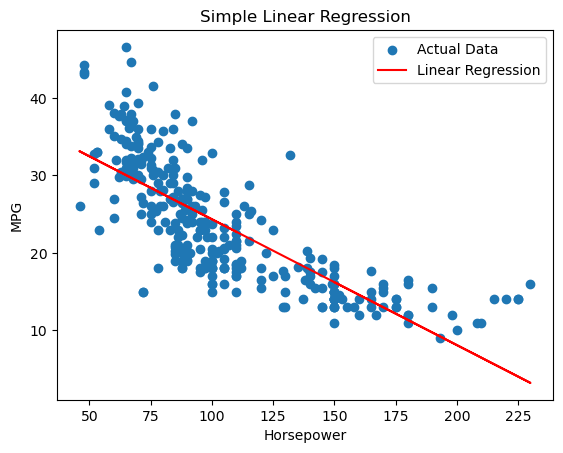

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_train)
y_pred1 = model.predict(X_test)

# Plot the data points and regression line
plt.scatter(X_train, y_train, label="Actual Data")

plt.plot(X_train, y_pred, color="red", label="Linear Regression")

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Simple Linear Regression")
plt.legend()

plt.show()

Evaluation on training data

In [27]:

# Evaluation metrics
print("MAE:", mean_absolute_error(y_train, y_pred))
print("MSE:", mean_squared_error(y_train, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_pred)))
print("R2 Score:", r2_score(y_train, y_pred))

MAE: 3.847347158741549
MSE: 24.475168273683455
RMSE: 4.947238449244534
R2 Score: 0.6121193728863612


#### Testing Data

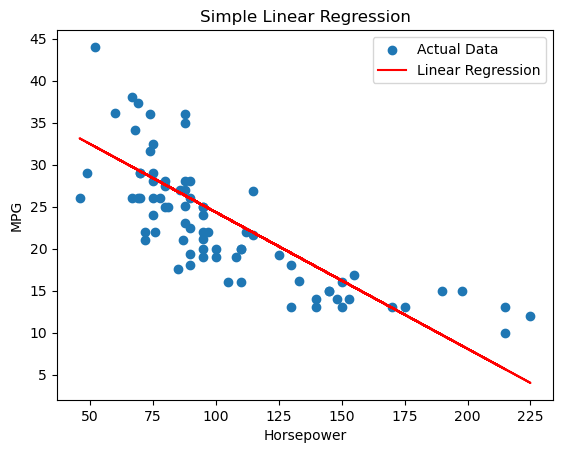

In [28]:
plt.scatter(X_test, y_test, label="Actual Data")

plt.plot(X_test, y_pred1, color="red", label="Linear Regression")

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Simple Linear Regression")
plt.legend()

plt.show()

Evaluation on testing data

In [29]:
# Evaluation metrics
print("MAE:", mean_absolute_error(y_test, y_pred1))
print("MSE:", mean_squared_error(y_test, y_pred1))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred1)))
print("R2 Score:", r2_score(y_test, y_pred1))

MAE: 3.7825127101269618
MSE: 22.153237123863423
RMSE: 4.706722545876634
R2 Score: 0.5659681822256183


### Polynomial Regression -- Degree 2

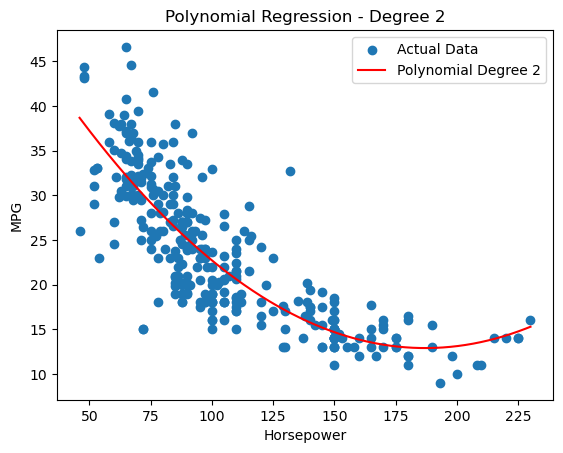

In [30]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model_poly2 = LinearRegression()

model_poly2.fit(X_train_poly, y_train)

y_pred_poly = model_poly2.predict(X_train_poly)
y_pred_poly2 = model_poly2.predict(X_test_poly)

# Plot the data points and polynomial curve
X_curve = pd.DataFrame({"horsepower": np.linspace(X.min().iloc[0], X.max().iloc[0], 300)})

X_curve_poly = poly.transform(X_curve)

y_curve = model_poly2.predict(X_curve_poly)

plt.scatter(X_train["horsepower"], y_train, label="Actual Data")

plt.plot(
    X_curve["horsepower"], y_curve,
    color="red", label="Polynomial Degree 2"
)

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Polynomial Regression - Degree 2")
plt.legend()

plt.show()

In [31]:
# Evaluation metrics
print("MAE:", mean_absolute_error(y_train, y_pred_poly))
print("MSE:", mean_squared_error(y_train, y_pred_poly))
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_pred_poly)))
print("R2 Score:", r2_score(y_train, y_pred_poly))

MAE: 3.2529925510616833
MSE: 19.20461369197704
RMSE: 4.382306891578572
R2 Score: 0.6956467257334956


In [32]:
# Evaluation metrics
print("MAE:", mean_absolute_error(y_test, y_pred_poly2))
print("MSE:", mean_squared_error(y_test, y_pred_poly2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_poly2)))
print("R2 Score:", r2_score(y_test, y_pred_poly2))

MAE: 3.264280823763113
MSE: 18.416967796017623
RMSE: 4.2914994810692475
R2 Score: 0.6391701147013344


### Polynomial Regression Degree 3

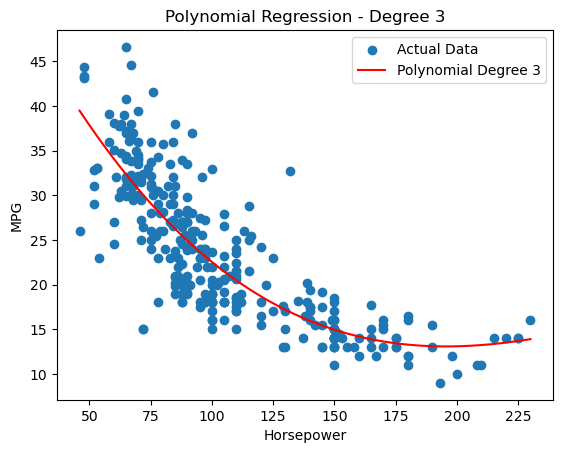

In [33]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=3)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model_poly2 = LinearRegression()

model_poly2.fit(X_train_poly, y_train)

y_pred_poly = model_poly2.predict(X_train_poly)
y_pred_poly2 = model_poly2.predict(X_test_poly)

# Plot the data points and polynomial curve
X_curve = pd.DataFrame({"horsepower": np.linspace(X.min().iloc[0], X.max().iloc[0], 300)})

X_curve_poly = poly.transform(X_curve)

y_curve = model_poly2.predict(X_curve_poly)

plt.scatter(X_train["horsepower"], y_train, label="Actual Data")

plt.plot(
    X_curve["horsepower"], y_curve,
    color="red", label="Polynomial Degree 3"
)

plt.xlabel("Horsepower")
plt.ylabel("MPG")
plt.title("Polynomial Regression - Degree 3")
plt.legend()

plt.show()

In [34]:
# Evaluation metrics
print("MAE:", mean_absolute_error(y_train, y_pred_poly))
print("MSE:", mean_squared_error(y_train, y_pred_poly))
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_pred_poly)))
print("R2 Score:", r2_score(y_train, y_pred_poly))

MAE: 3.245664812714156
MSE: 19.143788034701604
RMSE: 4.375361474747155
R2 Score: 0.6966106861780073


In [35]:
# Evaluation metrics
print("MAE:", mean_absolute_error(y_test, y_pred_poly2))
print("MSE:", mean_squared_error(y_test, y_pred_poly2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_poly2)))
print("R2 Score:", r2_score(y_test, y_pred_poly2))

MAE: 3.244682672639937
MSE: 18.46026722226034
RMSE: 4.2965413092696245
R2 Score: 0.6383217814046864
